# 1. Google Drive Setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# 2. Google Drive Contents

In [ ]:
import os

base_path = "/content/drive/MyDrive"

print(os.listdir(base_path))

['Screenshot_20231114_132139.jpg', 'Web Development Capstone.pdf', 'New folder', 'FRONT[1][1].gdoc', 'Coursera X7IHTA2A2MEF.pdf', 'Untitled document.gdoc', 'Coursera E59SEBBFEXFD.pdf', 'IMG_20250419_211901.jpg', 'IMG_20250419_211920.jpg', 'MLBD certificate .pdf', 'Adhar Card.pdf', 'SSA certificate .pdf', 'lipika.report.pdf', 'EDUCATIONAL TECHNOLOGY ppt 5th.pptx', 'EDUCATIONAL TECHNOLOGY ppt 5th.pdf', '. operating system pdf.pdf', 'IMG-20251120-WA0015.jpg', 'LIPIKA RESUME.pdf', 'Lipika Pati Resume.pdf', 'Lipika Resume .pdf', 'IMG_20260714_103501.jpg', 'IMG_20260714_104218.jpg', 'Classroom', 'Lipika Pati Project', 'Lipika Assignment', 'Colab Notebooks', 'knime-workspace.zip', 'XrayDataset', 'Lecture_1_5 (1).gdoc', 'Lecture_1_5.gdoc', 'XrayDataset_checkpoints']


# 3. Dataset Path and Contents

In [ ]:
dataset_path = "/content/drive/MyDrive/XrayDataset"

print("Dataset contents:")
print(os.listdir(dataset_path))

Dataset contents:
['Pneumonia_Viral', 'Tuberculosis', 'Pneumonia_Bacterial', 'Normal']


# 4. Google Drive Accessibility Verification

In [ ]:
import os

# This just LISTS what's inside your main Google Drive folder.
# It does NOT mount, remount, or change anything.
drive_root = "/content/drive/MyDrive"

if os.path.exists(drive_root):
    print("✅ Google Drive is accessible.")
    print("Top-level folders/files inside 'MyDrive':")
    for item in os.listdir(drive_root):
        print(" -", item)
else:
    print("❌ Could not find /content/drive/MyDrive.")
    print("Your Drive may not actually be mounted in this runtime.")

✅ Google Drive is accessible.
Top-level folders/files inside 'MyDrive':
 - Screenshot_20231114_132139.jpg
 - Web Development Capstone.pdf
 - New folder
 - FRONT[1][1].gdoc
 - Coursera X7IHTA2A2MEF.pdf
 - Untitled document.gdoc
 - Coursera E59SEBBFEXFD.pdf
 - IMG_20250419_211901.jpg
 - IMG_20250419_211920.jpg
 - MLBD certificate .pdf
 - Adhar Card.pdf
 - SSA certificate .pdf
 - lipika.report.pdf
 - EDUCATIONAL TECHNOLOGY ppt 5th.pptx
 - EDUCATIONAL TECHNOLOGY ppt 5th.pdf
 - . operating system pdf.pdf
 - IMG-20251120-WA0015.jpg
 - LIPIKA RESUME.pdf
 - Lipika Pati Resume.pdf
 - Lipika Resume .pdf
 - IMG_20260714_103501.jpg
 - IMG_20260714_104218.jpg
 - Classroom
 - Lipika Pati Project
 - Lipika Assignment
 - Colab Notebooks
 - knime-workspace.zip
 - XrayDataset
 - Lecture_1_5 (1).gdoc
 - Lecture_1_5.gdoc
 - XrayDataset_checkpoints


# 5. Dataset and Class Folder Verification

In [ ]:
import os

# This is the exact path to your dataset folder.
dataset_path = "/content/drive/MyDrive/XrayDataset"

expected_classes = ["Normal", "Pneumonia_Bacterial", "Pneumonia_Viral", "Tuberculosis"]

print(f"Looking inside: {dataset_path}\n")

if not os.path.exists(dataset_path):
    print("❌ This path does not exist. Double-check the folder name/location.")
else:
    print("✅ Dataset folder found.")
    actual_items = os.listdir(dataset_path)
    print("\nEverything found inside XrayDataset:")
    for item in actual_items:
        print(" -", item)

    print("\nChecking each expected class folder:")
    for class_name in expected_classes:
        class_path = os.path.join(dataset_path, class_name)
        if os.path.isdir(class_path):
            print(f"  ✅ '{class_name}' folder found.")
        else:
            print(f"  ❌ '{class_name}' folder NOT found at expected name.")

Looking inside: /content/drive/MyDrive/XrayDataset

✅ Dataset folder found.

Everything found inside XrayDataset:
 - Pneumonia_Viral
 - Tuberculosis
 - Pneumonia_Bacterial
 - Normal

Checking each expected class folder:
  ✅ 'Normal' folder found.
  ✅ 'Pneumonia_Bacterial' folder found.
  ✅ 'Pneumonia_Viral' folder found.
  ✅ 'Tuberculosis' folder found.


# 6. Image Count per Class

In [ ]:
import os

dataset_path = "/content/drive/MyDrive/XrayDataset"
class_names = ["Normal", "Pneumonia_Bacterial", "Pneumonia_Viral", "Tuberculosis"]

# These are the file "extensions" (the letters after the dot in a filename,
# like .jpg or .png) that count as valid images for us.
valid_extensions = (".jpg", ".jpeg", ".png", ".bmp")

class_counts = {}

for class_name in class_names:
    class_path = os.path.join(dataset_path, class_name)
    files = os.listdir(class_path)
    # Keep only files that end in one of our valid image extensions
    image_files = [f for f in files if f.lower().endswith(valid_extensions)]
    class_counts[class_name] = len(image_files)

print("Image count per class:\n")
for class_name, count in class_counts.items():
    print(f"  {class_name}: {count} images")

total_images = sum(class_counts.values())
print(f"\nTotal images across all 4 classes: {total_images}")

Image count per class:

  Normal: 1500 images
  Pneumonia_Bacterial: 3001 images
  Pneumonia_Viral: 1500 images
  Tuberculosis: 1500 images

Total images across all 4 classes: 7501


# 7. Image Format and Corrupted Image Check

In [ ]:
import os
from PIL import Image

dataset_path = "/content/drive/MyDrive/XrayDataset"
class_names = ["Normal", "Pneumonia_Bacterial", "Pneumonia_Viral", "Tuberculosis"]
valid_extensions = (".jpg", ".jpeg", ".png", ".bmp")

extension_counts = {}
corrupted_files = []
checked_count = 0

for class_name in class_names:
    class_path = os.path.join(dataset_path, class_name)
    files = [f for f in os.listdir(class_path) if f.lower().endswith(valid_extensions)]

    for fname in files:
        # Track which extension this file uses
        ext = os.path.splitext(fname)[1].lower()
        extension_counts[ext] = extension_counts.get(ext, 0) + 1

        # Try to actually open the image to check it's not broken
        fpath = os.path.join(class_path, fname)
        try:
            img = Image.open(fpath)
            img.verify()  # checks the file is a valid, complete image
        except Exception as e:
            corrupted_files.append((class_name, fname, str(e)))

        checked_count += 1
        if checked_count % 1000 == 0:
            print(f"Checked {checked_count} images so far...")

print("\n--- Extensions found in dataset ---")
for ext, count in extension_counts.items():
    print(f"  {ext}: {count} files")

print(f"\n--- Corruption check complete ---")
print(f"Total images checked: {checked_count}")
print(f"Corrupted/unreadable images found: {len(corrupted_files)}")

if corrupted_files:
    print("\nList of corrupted files:")
    for class_name, fname, error in corrupted_files:
        print(f"  [{class_name}] {fname} -> {error}")
else:
    print("✅ No corrupted images found.")

Checked 1000 images so far...
Checked 2000 images so far...
Checked 3000 images so far...
Checked 4000 images so far...
Checked 5000 images so far...
Checked 6000 images so far...
Checked 7000 images so far...

--- Extensions found in dataset ---
  .jpg: 6001 files
  .png: 1500 files

--- Corruption check complete ---
Total images checked: 7501
Corrupted/unreadable images found: 0
✅ No corrupted images found.


# 8. Image Dimensions and Color Mode Analysis

In [ ]:
import os
from PIL import Image
from collections import Counter

dataset_path = "/content/drive/MyDrive/XrayDataset"
class_names = ["Normal", "Pneumonia_Bacterial", "Pneumonia_Viral", "Tuberculosis"]
valid_extensions = (".jpg", ".jpeg", ".png", ".bmp")

dimensions = []       # will store (width, height) for every image
color_modes = Counter()  # will count how many images are RGB, grayscale, etc.
checked_count = 0

for class_name in class_names:
    class_path = os.path.join(dataset_path, class_name)
    files = [f for f in os.listdir(class_path) if f.lower().endswith(valid_extensions)]

    for fname in files:
        fpath = os.path.join(class_path, fname)
        try:
            with Image.open(fpath) as img:
                dimensions.append(img.size)   # (width, height)
                color_modes[img.mode] += 1    # e.g. 'RGB', 'L' (grayscale), 'RGBA'
        except Exception as e:
            print(f"Skipped unreadable file: {fname} -> {e}")

        checked_count += 1
        if checked_count % 1000 == 0:
            print(f"Checked {checked_count} images so far...")

widths = [w for w, h in dimensions]
heights = [h for w, h in dimensions]

print("\n--- Dimension Statistics ---")
print(f"Smallest width x height:  {min(widths)} x {min(heights)}")
print(f"Largest width x height:   {max(widths)} x {max(heights)}")

most_common_sizes = Counter(dimensions).most_common(5)
print("\nMost common (width x height) sizes:")
for size, count in most_common_sizes:
    print(f"  {size[0]} x {size[1]}  ->  appears {count} times")

print("\n--- Color Mode Statistics ---")
for mode, count in color_modes.items():
    print(f"  Mode '{mode}': {count} images")

Checked 1000 images so far...
Checked 2000 images so far...
Checked 3000 images so far...
Checked 4000 images so far...
Checked 5000 images so far...
Checked 6000 images so far...
Checked 7000 images so far...

--- Dimension Statistics ---
Smallest width x height:  144 x 127
Largest width x height:   2772 x 2863

Most common (width x height) sizes:
  400 x 300  ->  appears 1055 times
  1024 x 1024  ->  appears 642 times
  256 x 211  ->  appears 386 times
  256 x 256  ->  appears 323 times
  211 x 256  ->  appears 133 times

--- Color Mode Statistics ---
  Mode 'RGB': 6534 images
  Mode 'L': 967 images


# 9. Class Distribution Visualization

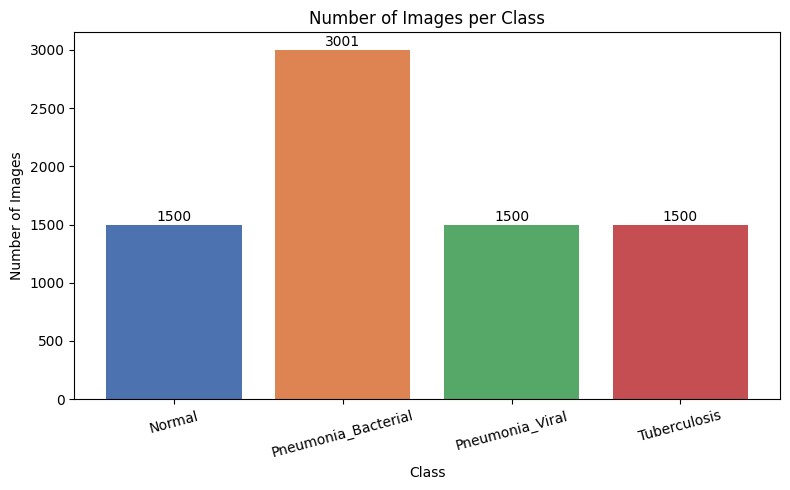

In [ ]:
import matplotlib.pyplot as plt

# These are the counts we already found in Cell 3
class_counts = {
    "Normal": 1500,
    "Pneumonia_Bacterial": 3001,
    "Pneumonia_Viral": 1500,
    "Tuberculosis": 1500
}

plt.figure(figsize=(8, 5))
plt.bar(class_counts.keys(), class_counts.values(), color=["#4C72B0", "#DD8452", "#55A868", "#C44E52"])
plt.title("Number of Images per Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=15)
for i, (name, count) in enumerate(class_counts.items()):
    plt.text(i, count + 30, str(count), ha="center")
plt.tight_layout()
plt.show()

# 10. Sample X-ray Images

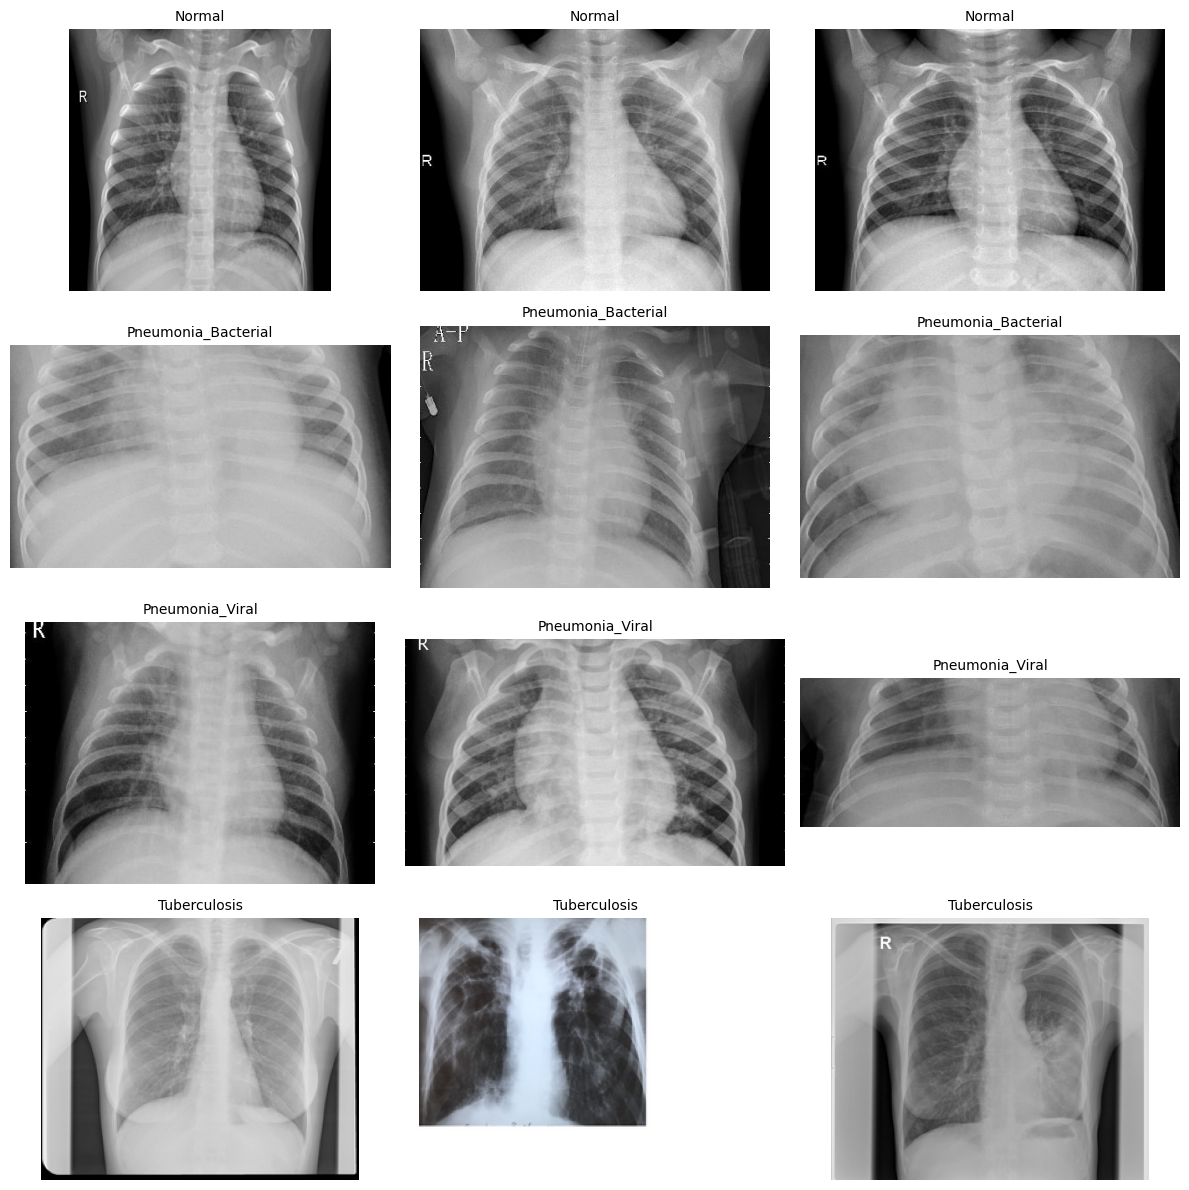

In [ ]:
import os
import random
from PIL import Image
import matplotlib.pyplot as plt

dataset_path = "/content/drive/MyDrive/XrayDataset"
class_names = ["Normal", "Pneumonia_Bacterial", "Pneumonia_Viral", "Tuberculosis"]
valid_extensions = (".jpg", ".jpeg", ".png", ".bmp")
samples_per_class = 3

fig, axes = plt.subplots(len(class_names), samples_per_class, figsize=(12, 12))

for row, class_name in enumerate(class_names):
    class_path = os.path.join(dataset_path, class_name)
    files = [f for f in os.listdir(class_path) if f.lower().endswith(valid_extensions)]
    sample_files = random.sample(files, samples_per_class)

    for col, fname in enumerate(sample_files):
        img_path = os.path.join(class_path, fname)
        img = Image.open(img_path)
        ax = axes[row, col]
        ax.imshow(img, cmap="gray" if img.mode == "L" else None)
        ax.set_title(class_name, fontsize=10)
        ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os
import random
import numpy as np
from sklearn.model_selection import train_test_split

# ---- Basic settings for this phase ----

# Path to your dataset (same as before, unchanged)
dataset_path = "/content/drive/MyDrive/XrayDataset"
class_names = ["Normal", "Pneumonia_Bacterial", "Pneumonia_Viral", "Tuberculosis"]
valid_extensions = (".jpg", ".jpeg", ".png", ".bmp")

# All images will eventually be resized to this size (width, height) in pixels.
# 224x224 is a very common size used with many pretrained deep learning models.
IMAGE_SIZE = (224, 224)

# How we split the data:
# 70% for training, 15% for validation, 15% for testing
TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

# A "seed" makes random splitting reproducible —
# meaning if we run this again, we get the exact same split every time.
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("✅ Libraries imported and settings configured.")
print(f"Image size for training: {IMAGE_SIZE}")
print(f"Split ratios -> Train: {TRAIN_RATIO}, Validation: {VAL_RATIO}, Test: {TEST_RATIO}")

✅ Libraries imported and settings configured.
Image size for training: (224, 224)
Split ratios -> Train: 0.7, Validation: 0.15, Test: 0.15


In [ ]:
all_filepaths = []   # will hold the full path to every image
all_labels = []       # will hold the matching class name for each image

for class_name in class_names:
    class_path = os.path.join(dataset_path, class_name)
    files = [f for f in os.listdir(class_path) if f.lower().endswith(valid_extensions)]

    for fname in files:
        full_path = os.path.join(class_path, fname)
        all_filepaths.append(full_path)
        all_labels.append(class_name)

print(f"✅ Collected {len(all_filepaths)} image paths in total.")
print("\nExample entries:")
for i in [0, 1, 2]:
    print(f"  Path: {all_filepaths[i]}")
    print(f"  Label: {all_labels[i]}\n")

# Quick check: does this match what we counted in Phase 1?
print("Count per class (double-check):")
for class_name in class_names:
    count = all_labels.count(class_name)
    print(f"  {class_name}: {count}")

✅ Collected 7501 image paths in total.

Example entries:
  Path: /content/drive/MyDrive/XrayDataset/Normal/Normal (2057).jpg
  Label: Normal

  Path: /content/drive/MyDrive/XrayDataset/Normal/Normal (2042).jpg
  Label: Normal

  Path: /content/drive/MyDrive/XrayDataset/Normal/Normal (2026).jpg
  Label: Normal

Count per class (double-check):
  Normal: 1500
  Pneumonia_Bacterial: 3001
  Pneumonia_Viral: 1500
  Tuberculosis: 1500


In [ ]:
# Step 1: Split off the Test set first (15%), keeping the remaining 85% for train+val
train_val_paths, test_paths, train_val_labels, test_labels = train_test_split(
    all_filepaths,
    all_labels,
    test_size=TEST_RATIO,
    stratify=all_labels,      # ensures each class keeps its proportion
    random_state=RANDOM_SEED
)

# Step 2: Split the remaining 85% into Train (70% of total) and Validation (15% of total)
# Since train_val is 85% of the total, we need val to be 15/85 of THIS subset
val_fraction_of_remainder = VAL_RATIO / (TRAIN_RATIO + VAL_RATIO)

train_paths, val_paths, train_labels, val_labels = train_test_split(
    train_val_paths,
    train_val_labels,
    test_size=val_fraction_of_remainder,
    stratify=train_val_labels,
    random_state=RANDOM_SEED
)

print("✅ Split complete.")
print(f"Training set:   {len(train_paths)} images")
print(f"Validation set: {len(val_paths)} images")
print(f"Test set:       {len(test_paths)} images")
print(f"Total:          {len(train_paths) + len(val_paths) + len(test_paths)} images")

✅ Split complete.
Training set:   5250 images
Validation set: 1125 images
Test set:       1126 images
Total:          7501 images


In [ ]:
from collections import Counter

def print_class_breakdown(name, labels):
    counts = Counter(labels)
    total = len(labels)
    print(f"{name} set ({total} images):")
    for class_name in class_names:
        count = counts.get(class_name, 0)
        percent = (count / total) * 100
        print(f"  {class_name}: {count}  ({percent:.1f}%)")
    print()

print_class_breakdown("Training", train_labels)
print_class_breakdown("Validation", val_labels)
print_class_breakdown("Test", test_labels)

Training set (5250 images):
  Normal: 1050  (20.0%)
  Pneumonia_Bacterial: 2100  (40.0%)
  Pneumonia_Viral: 1050  (20.0%)
  Tuberculosis: 1050  (20.0%)

Validation set (1125 images):
  Normal: 225  (20.0%)
  Pneumonia_Bacterial: 450  (40.0%)
  Pneumonia_Viral: 225  (20.0%)
  Tuberculosis: 225  (20.0%)

Test set (1126 images):
  Normal: 225  (20.0%)
  Pneumonia_Bacterial: 451  (40.1%)
  Pneumonia_Viral: 225  (20.0%)
  Tuberculosis: 225  (20.0%)



In [ ]:
import torch
from torchvision import transforms

# These numbers are standard normalization values used by most pretrained
# vision models (based on a huge dataset called ImageNet). Using them helps
# if we later use transfer learning with a pretrained backbone.
NORM_MEAN = [0.485, 0.456, 0.406]
NORM_STD = [0.229, 0.224, 0.225]

# ---- Transform for TRAINING images (includes augmentation) ----
train_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.Grayscale(num_output_channels=3),   # ensures grayscale images become 3-channel too
    transforms.RandomHorizontalFlip(p=0.3),         # mild chance of flipping left-right
    transforms.RandomRotation(degrees=10),          # small random rotation, +/-10 degrees
    transforms.ColorJitter(brightness=0.1, contrast=0.1),  # slight brightness/contrast variation
    transforms.ToTensor(),                          # converts image to a PyTorch tensor (number grid)
    transforms.Normalize(mean=NORM_MEAN, std=NORM_STD)
])

# ---- Transform for VALIDATION and TEST images (no augmentation) ----
eval_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=NORM_MEAN, std=NORM_STD)
])

print("✅ Transforms defined.")
print("Training images will be resized, mildly augmented, and normalized.")
print("Validation/Test images will be resized and normalized only (no augmentation).")

✅ Transforms defined.
Training images will be resized, mildly augmented, and normalized.
Validation/Test images will be resized and normalized only (no augmentation).


In [ ]:
from torch.utils.data import Dataset, DataLoader
from PIL import Image

# Maps each class name to a number, since models work with numbers, not text labels.
# Example: Normal -> 0, Pneumonia_Bacterial -> 1, Pneumonia_Viral -> 2, Tuberculosis -> 3
class_to_idx = {name: idx for idx, name in enumerate(class_names)}
print("Class-to-number mapping:", class_to_idx)

class XrayDataset(Dataset):
    def __init__(self, filepaths, labels, transform):
        self.filepaths = filepaths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        # Tells PyTorch how many images are in this dataset
        return len(self.filepaths)

    def __getitem__(self, index):
        # Tells PyTorch how to load ONE image + its label, given a position number
        img_path = self.filepaths[index]
        label_name = self.labels[index]
        label_number = class_to_idx[label_name]

        image = Image.open(img_path).convert("RGB")  # ensures 3-channel before transform
        image = self.transform(image)

        return image, label_number

# ---- Create the three datasets ----
train_dataset = XrayDataset(train_paths, train_labels, train_transform)
val_dataset = XrayDataset(val_paths, val_labels, eval_transform)
test_dataset = XrayDataset(test_paths, test_labels, eval_transform)

# ---- Create the three data loaders ----
BATCH_SIZE = 32  # how many images are processed together at once during training

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"\n✅ Datasets and DataLoaders created.")
print(f"Training batches per epoch:   {len(train_loader)}")
print(f"Validation batches per epoch: {len(val_loader)}")
print(f"Test batches:                 {len(test_loader)}")

Class-to-number mapping: {'Normal': 0, 'Pneumonia_Bacterial': 1, 'Pneumonia_Viral': 2, 'Tuberculosis': 3}

✅ Datasets and DataLoaders created.
Training batches per epoch:   165
Validation batches per epoch: 36
Test batches:                 36


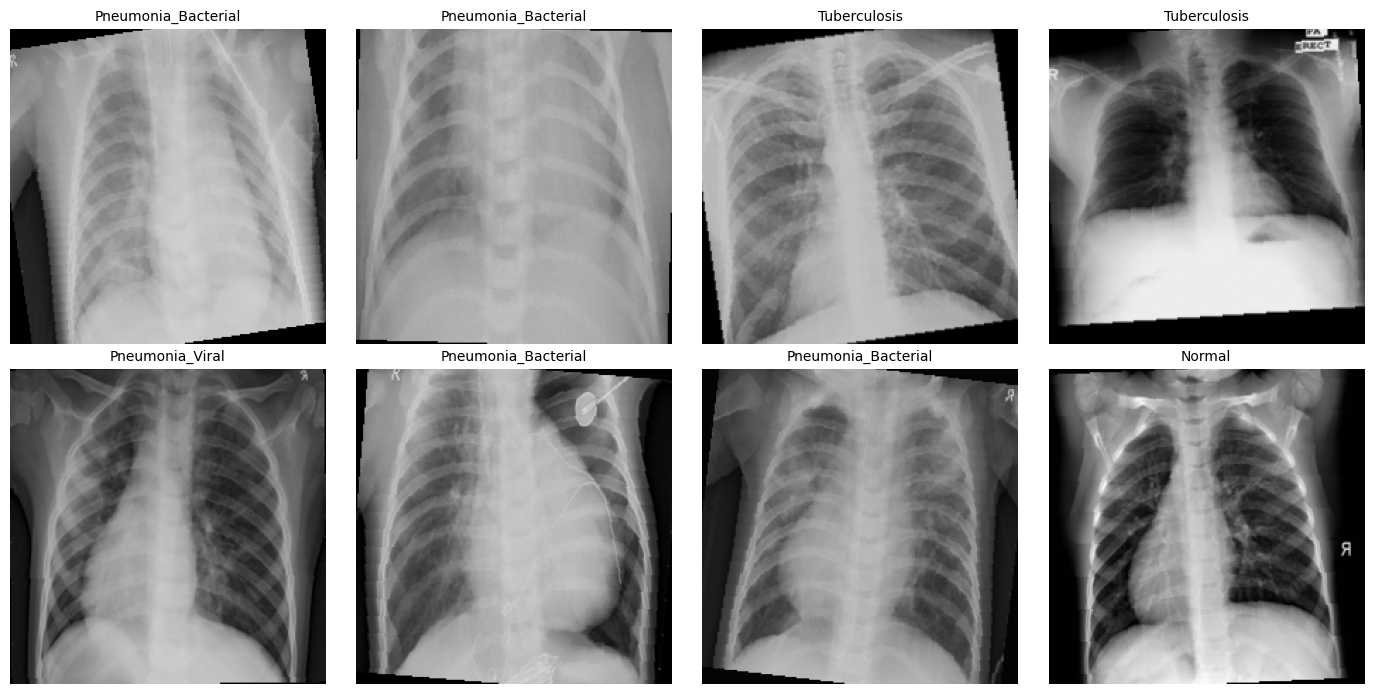

Batch shape: torch.Size([32, 3, 224, 224])
Labels in this batch: ['Pneumonia_Bacterial', 'Pneumonia_Bacterial', 'Tuberculosis', 'Tuberculosis', 'Pneumonia_Viral', 'Pneumonia_Bacterial', 'Pneumonia_Bacterial', 'Normal', 'Pneumonia_Viral', 'Normal', 'Normal', 'Pneumonia_Viral', 'Pneumonia_Bacterial', 'Normal', 'Normal', 'Tuberculosis', 'Tuberculosis', 'Pneumonia_Viral', 'Pneumonia_Viral', 'Pneumonia_Bacterial', 'Pneumonia_Bacterial', 'Tuberculosis', 'Pneumonia_Bacterial', 'Normal', 'Tuberculosis', 'Normal', 'Pneumonia_Bacterial', 'Pneumonia_Bacterial', 'Normal', 'Normal', 'Pneumonia_Viral', 'Pneumonia_Viral']


In [ ]:
import matplotlib.pyplot as plt

# Get one batch from the training loader
images, labels = next(iter(train_loader))

# Reverse the normalization so images display with normal-looking brightness/color
def unnormalize(img_tensor):
    mean = torch.tensor(NORM_MEAN).view(3, 1, 1)
    std = torch.tensor(NORM_STD).view(3, 1, 1)
    return img_tensor * std + mean

idx_to_class = {v: k for k, v in class_to_idx.items()}

num_to_show = 8
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i in range(num_to_show):
    img = unnormalize(images[i]).permute(1, 2, 0).numpy()  # rearrange for display
    img = img.clip(0, 1)  # keep pixel values in valid display range

    ax = axes[i // 4, i % 4]
    ax.imshow(img)
    label_name = idx_to_class[labels[i].item()]
    ax.set_title(label_name, fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()

print(f"Batch shape: {images.shape}")  # should be [32, 3, 224, 224]
print(f"Labels in this batch: {[idx_to_class[l.item()] for l in labels]}")

Feature Extractor Backbone (CNN)

In [ ]:
import torch
import torch.nn as nn
import torchvision.models as models

class CNNBackbone(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()
        # Load ResNet-18, pretrained on ImageNet (a huge general-purpose image dataset)
        resnet = models.resnet18(weights="IMAGENET1K_V1" if pretrained else None)

        # Remove the last two layers: the average-pooling and final classification layer.
        # We only want the CONVOLUTIONAL feature-extracting part, not its final "guess".
        self.feature_extractor = nn.Sequential(*list(resnet.children())[:-2])

    def forward(self, x):
        # Input x shape:  [batch_size, 3, 224, 224]
        features = self.feature_extractor(x)
        # Output shape: [batch_size, 512, 7, 7]
        # Meaning: for each image, a 7x7 grid of "locations",
        # each described by 512 learned numbers (channels).
        return features

# Quick shape test with fake random data (not your real images yet)
backbone = CNNBackbone(pretrained=True)
dummy_input = torch.randn(2, 3, 224, 224)  # pretend batch of 2 images
with torch.no_grad():
    output = backbone(dummy_input)

print("✅ Backbone created successfully.")
print(f"Input shape:  {dummy_input.shape}")
print(f"Output shape: {output.shape}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 183MB/s]


✅ Backbone created successfully.
Input shape:  torch.Size([2, 3, 224, 224])
Output shape: torch.Size([2, 512, 7, 7])


Tokenize Feature Grid + Add Positional Encoding

In [ ]:
import math

class PositionalEncoding(nn.Module):
    def __init__(self, num_tokens, embed_dim):
        super().__init__()
        # A learnable positional embedding: one unique vector per token position.
        # The model will learn during training what these positions should represent.
        self.pos_embedding = nn.Parameter(torch.zeros(1, num_tokens, embed_dim))
        nn.init.trunc_normal_(self.pos_embedding, std=0.02)

    def forward(self, x):
        # x shape: [batch_size, num_tokens, embed_dim]
        return x + self.pos_embedding


class ImageTokenizer(nn.Module):
    def __init__(self, embed_dim=512, grid_size=7):
        super().__init__()
        self.num_tokens = grid_size * grid_size  # 7*7 = 49
        self.pos_encoding = PositionalEncoding(self.num_tokens, embed_dim)

    def forward(self, feature_map):
        # feature_map shape: [batch_size, 512, 7, 7]  (output of the CNN backbone)
        batch_size, channels, h, w = feature_map.shape

        # Flatten the 7x7 grid into a sequence of 49 tokens
        tokens = feature_map.flatten(2)          # -> [batch_size, 512, 49]
        tokens = tokens.permute(0, 2, 1)          # -> [batch_size, 49, 512]

        # Add positional information to each token
        tokens = self.pos_encoding(tokens)
        return tokens

# ---- Quick shape test, continuing from Cell 1's dummy output ----
tokenizer = ImageTokenizer(embed_dim=512, grid_size=7)
with torch.no_grad():
    token_sequence = tokenizer(output)  # 'output' is the CNN feature map from Cell 1

print("✅ Tokenizer created successfully.")
print(f"CNN feature map shape: {output.shape}")
print(f"Token sequence shape:  {token_sequence.shape}")

✅ Tokenizer created successfully.
CNN feature map shape: torch.Size([2, 512, 7, 7])
Token sequence shape:  torch.Size([2, 49, 512])


ProbSparse Self-Attention (Informer's Core Mechanism)

In [ ]:
class ProbSparseAttention(nn.Module):
    def __init__(self, embed_dim, num_heads, sample_factor=5):
        super().__init__()
        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.sample_factor = sample_factor  # controls how many queries we treat as "top"

        # Standard learned projections, same as in a normal Transformer
        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.k_proj = nn.Linear(embed_dim, embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)
        self.out_proj = nn.Linear(embed_dim, embed_dim)

    def _split_heads(self, x, batch_size):
        # Reshapes [batch, seq_len, embed_dim] -> [batch, num_heads, seq_len, head_dim]
        # This lets multiple "attention heads" look at the data differently, in parallel.
        seq_len = x.shape[1]
        x = x.view(batch_size, seq_len, self.num_heads, self.head_dim)
        return x.permute(0, 2, 1, 3)

    def forward(self, x):
        # x shape: [batch_size, seq_len, embed_dim]  (e.g. [2, 49, 512])
        batch_size, seq_len, _ = x.shape

        Q = self._split_heads(self.q_proj(x), batch_size)  # queries: "what am I looking for?"
        K = self._split_heads(self.k_proj(x), batch_size)  # keys:    "what do I contain?"
        V = self._split_heads(self.v_proj(x), batch_size)  # values:  "what do I actually provide?"

        # ---- Step 1: measure how "informative" each query is ----
        # We estimate this using the max attention score a query could get vs the average
        # (a query that stands out sharply from the average is more "informative").
        scores_sample = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.head_dim)
        max_score = scores_sample.max(dim=-1)[0]
        mean_score = scores_sample.mean(dim=-1)
        sparsity_measure = max_score - mean_score  # higher = more informative query

        # ---- Step 2: keep only the top-u most informative queries ----
        u = max(1, int(self.sample_factor * math.log(seq_len)))
        u = min(u, seq_len)  # never select more queries than actually exist
        top_indices = sparsity_measure.topk(u, dim=-1)[1]  # positions of top queries per head

        # ---- Step 3: compute FULL attention only for the top queries ----
        Q_reduced = torch.gather(
            Q, 2, top_indices.unsqueeze(-1).expand(-1, -1, -1, self.head_dim)
        )
        attn_scores = torch.matmul(Q_reduced, K.transpose(-2, -1)) / math.sqrt(self.head_dim)
        attn_weights = torch.softmax(attn_scores, dim=-1)
        attn_output_top = torch.matmul(attn_weights, V)

        # ---- Step 4: for the REMAINING (non-top) queries, use a cheap default ----
        # This default is just the average of all values — a reasonable "best guess"
        # for tokens that weren't informative enough to deserve full attention.
        default_output = V.mean(dim=2, keepdim=True).expand(-1, -1, seq_len, -1)

        # ---- Step 5: combine both into the final output, in the correct original order ----
        output = default_output.clone()
        output.scatter_(
            2, top_indices.unsqueeze(-1).expand(-1, -1, -1, self.head_dim), attn_output_top
        )

        # Merge attention heads back into one combined representation
        output = output.permute(0, 2, 1, 3).contiguous().view(batch_size, seq_len, self.embed_dim)
        return self.out_proj(output)

# ---- Quick shape test, continuing from Cell 2's token sequence ----
attention = ProbSparseAttention(embed_dim=512, num_heads=8, sample_factor=5)
with torch.no_grad():
    attn_output = attention(token_sequence)

print("✅ ProbSparse Attention created successfully.")
print(f"Input shape:  {token_sequence.shape}")
print(f"Output shape: {attn_output.shape}")
print(f"(Number of tokens selected for full attention per head, u = {max(1, int(5 * math.log(49)))})")

✅ ProbSparse Attention created successfully.
Input shape:  torch.Size([2, 49, 512])
Output shape: torch.Size([2, 49, 512])
(Number of tokens selected for full attention per head, u = 19)


Full Informer Encoder Layer (with Distilling)

In [ ]:
class InformerEncoderLayer(nn.Module):
    def __init__(self, embed_dim, num_heads, ff_dim=1024, sample_factor=5, dropout=0.1):
        super().__init__()
        self.attention = ProbSparseAttention(embed_dim, num_heads, sample_factor)

        # Standard Transformer feed-forward block: expand, activate, shrink back
        self.feed_forward = nn.Sequential(
            nn.Linear(embed_dim, ff_dim),
            nn.GELU(),
            nn.Linear(ff_dim, embed_dim)
        )

        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.dropout = nn.Dropout(dropout)

        # Distilling: a 1D convolution + max-pooling that shrinks the sequence length by half.
        # This lets deeper layers focus on fewer, more "distilled" tokens.
        self.distill_conv = nn.Conv1d(embed_dim, embed_dim, kernel_size=3, padding=1)
        self.distill_norm = nn.BatchNorm1d(embed_dim)
        self.distill_pool = nn.MaxPool1d(kernel_size=2, stride=2)

    def forward(self, x):
        # x shape: [batch_size, seq_len, embed_dim]

        # ---- Attention block (with residual connection + normalization) ----
        attn_out = self.attention(x)
        x = self.norm1(x + self.dropout(attn_out))

        # ---- Feed-forward block (with residual connection + normalization) ----
        ff_out = self.feed_forward(x)
        x = self.norm2(x + self.dropout(ff_out))

        # ---- Distilling: shrink the sequence length ----
        x_conv = x.permute(0, 2, 1)              # -> [batch, embed_dim, seq_len] for Conv1d
        x_conv = self.distill_conv(x_conv)
        x_conv = self.distill_norm(x_conv)
        x_conv = torch.relu(x_conv)
        x_conv = self.distill_pool(x_conv)        # sequence length is halved here
        x_distilled = x_conv.permute(0, 2, 1)     # -> back to [batch, new_seq_len, embed_dim]

        return x_distilled

# ---- Quick shape test, continuing from Cell 3's attention output ----
encoder_layer = InformerEncoderLayer(embed_dim=512, num_heads=8, ff_dim=1024, sample_factor=5)
with torch.no_grad():
    layer_output = encoder_layer(token_sequence)

print("✅ Informer Encoder Layer created successfully.")
print(f"Input shape:  {token_sequence.shape}")
print(f"Output shape: {layer_output.shape}")
print("(Notice the sequence length shrank due to distilling)")

✅ Informer Encoder Layer created successfully.
Input shape:  torch.Size([2, 49, 512])
Output shape: torch.Size([2, 24, 512])
(Notice the sequence length shrank due to distilling)


Complete Model: CNN + Informer Stack + Classifier

In [ ]:
class ChestXrayInformer(nn.Module):
    def __init__(self, num_classes=4, embed_dim=512, num_heads=8,
                 ff_dim=1024, num_layers=2, sample_factor=5, dropout=0.1):
        super().__init__()

        self.backbone = CNNBackbone(pretrained=True)
        self.tokenizer = ImageTokenizer(embed_dim=embed_dim, grid_size=7)

        # Stack multiple Informer encoder layers.
        # Each layer's output feeds into the next (and the sequence keeps shrinking).
        self.encoder_layers = nn.ModuleList([
            InformerEncoderLayer(embed_dim, num_heads, ff_dim, sample_factor, dropout)
            for _ in range(num_layers)
        ])

        # After all encoder layers, we average across the remaining tokens
        # to get ONE summary vector per image, then classify it.
        self.classifier = nn.Sequential(
            nn.LayerNorm(embed_dim),
            nn.Linear(embed_dim, embed_dim // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(embed_dim // 2, num_classes)
        )

    def forward(self, x):
        # x shape: [batch_size, 3, 224, 224]  (a batch of preprocessed X-ray images)

        features = self.backbone(x)              # -> [batch, 512, 7, 7]
        tokens = self.tokenizer(features)         # -> [batch, 49, 512]

        for layer in self.encoder_layers:
            tokens = layer(tokens)                # sequence shrinks at each layer

        # Average all remaining tokens into one summary vector per image
        summary = tokens.mean(dim=1)              # -> [batch, 512]

        logits = self.classifier(summary)         # -> [batch, num_classes]
        return logits

# ---- Build the model with 2 Informer encoder layers ----
model = ChestXrayInformer(num_classes=4, embed_dim=512, num_heads=8,
                           ff_dim=1024, num_layers=2, sample_factor=5)

print("✅ Full ChestXrayInformer model created successfully.")

✅ Full ChestXrayInformer model created successfully.


End-to-End Shape Test with a Dummy Batch

In [ ]:
# Simulate a realistic batch, same shape as what your real train_loader produces
BATCH_SIZE_TEST = 8
dummy_batch = torch.randn(BATCH_SIZE_TEST, 3, 224, 224)

model.eval()  # sets the model to evaluation mode (disables dropout, etc. for this test)
with torch.no_grad():
    predictions = model(dummy_batch)

print("✅ Full forward pass completed successfully.")
print(f"Input batch shape:  {dummy_batch.shape}")
print(f"Output shape:       {predictions.shape}")
print(f"Expected output:    [batch_size={BATCH_SIZE_TEST}, num_classes=4]")

print("\nExample raw output scores for image 0 (before softmax):")
print(predictions[0])

# Convert raw scores into probabilities, just to see it makes sense
probs = torch.softmax(predictions[0], dim=0)
print("\nAs probabilities (should sum to 1.0):")
for i, class_name in enumerate(class_names):
    print(f"  {class_name}: {probs[i].item():.3f}")

✅ Full forward pass completed successfully.
Input batch shape:  torch.Size([8, 3, 224, 224])
Output shape:       torch.Size([8, 4])
Expected output:    [batch_size=8, num_classes=4]

Example raw output scores for image 0 (before softmax):
tensor([ 0.0296,  0.4185, -0.1829,  0.1735])

As probabilities (should sum to 1.0):
  Normal: 0.225
  Pneumonia_Bacterial: 0.332
  Pneumonia_Viral: 0.182
  Tuberculosis: 0.260


Model Parameter Summary

In [ ]:
def count_parameters(module):
    return sum(p.numel() for p in module.parameters() if p.requires_grad)

backbone_params = count_parameters(model.backbone)
tokenizer_params = count_parameters(model.tokenizer)
encoder_params = count_parameters(model.encoder_layers)
classifier_params = count_parameters(model.classifier)
total_params = count_parameters(model)

print("--- Model Parameter Summary ---")
print(f"CNN Backbone:        {backbone_params:,} parameters")
print(f"Tokenizer (pos enc): {tokenizer_params:,} parameters")
print(f"Informer Encoder(s): {encoder_params:,} parameters")
print(f"Classifier Head:     {classifier_params:,} parameters")
print(f"{'-'*40}")
print(f"TOTAL:                {total_params:,} parameters")

--- Model Parameter Summary ---
CNN Backbone:        11,176,512 parameters
Tokenizer (pos enc): 25,088 parameters
Informer Encoder(s): 5,781,504 parameters
Classifier Head:     133,380 parameters
----------------------------------------
TOTAL:                17,116,484 parameters


Training Setup

In [ ]:
import torch.optim as optim

# ---- Step 1: Pick GPU if available, otherwise CPU ----
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
print(f"Using device: {device}")

# ---- Step 2: Loss function with class weighting ----
# We calculate weights so underrepresented classes count MORE in the loss,
# helping the model not just default to predicting the majority class.
class_sample_counts = [train_labels.count(c) for c in class_names]
total_train_samples = len(train_labels)
class_weights = [total_train_samples / (len(class_names) * count) for count in class_sample_counts]
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)

print("\nClass weights (higher = rarer class, counted more heavily):")
for name, weight in zip(class_names, class_weights):
    print(f"  {name}: {weight:.3f}")

criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

# ---- Step 3: Optimizer ----
# Adam is a widely-used, reliable choice for training deep learning models.
LEARNING_RATE = 1e-4
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# ---- Step 4: Learning rate scheduler ----
# Reduces the learning rate when validation loss stops improving,
# helping the model fine-tune more gently in later stages of training.
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=2
)

print(f"\n✅ Training setup complete.")
print(f"Optimizer: Adam, Learning rate: {LEARNING_RATE}")
print(f"Scheduler: ReduceLROnPlateau (halves LR if val loss plateaus for 2 epochs)")

Using device: cuda

Class weights (higher = rarer class, counted more heavily):
  Normal: 1.250
  Pneumonia_Bacterial: 0.625
  Pneumonia_Viral: 1.250
  Tuberculosis: 1.250

✅ Training setup complete.
Optimizer: Adam, Learning rate: 0.0001
Scheduler: ReduceLROnPlateau (halves LR if val loss plateaus for 2 epochs)


Checkpointing & Early Stopping Helpers

In [ ]:
class EarlyStoppingAndCheckpoint:
    def __init__(self, patience=5, checkpoint_path="/content/drive/MyDrive/XrayDataset_checkpoints/best_model.pth"):
        self.patience = patience              # how many epochs to wait without improvement
        self.checkpoint_path = checkpoint_path
        self.best_val_loss = float("inf")     # starts as "infinitely bad" so any real result beats it
        self.epochs_without_improvement = 0
        self.should_stop = False

        # Make sure the folder for saving checkpoints exists
        os.makedirs(os.path.dirname(checkpoint_path), exist_ok=True)

    def check(self, val_loss, model, epoch):
        if val_loss < self.best_val_loss:
            # New best result — save it and reset the "patience" counter
            self.best_val_loss = val_loss
            self.epochs_without_improvement = 0
            torch.save(model.state_dict(), self.checkpoint_path)
            print(f"  ✅ New best validation loss ({val_loss:.4f}) — model checkpoint saved.")
        else:
            self.epochs_without_improvement += 1
            print(f"  No improvement for {self.epochs_without_improvement} epoch(s) "
                  f"(best so far: {self.best_val_loss:.4f})")

            if self.epochs_without_improvement >= self.patience:
                self.should_stop = True
                print(f"  ⏹ Early stopping triggered after {self.patience} epochs without improvement.")

# Create one instance of this helper to use during training
early_stopper = EarlyStoppingAndCheckpoint(patience=5)

print("✅ Checkpointing and early stopping ready.")
print(f"Checkpoints will be saved to: {early_stopper.checkpoint_path}")
print(f"Training will stop early if validation loss doesn't improve for {early_stopper.patience} epochs.")

✅ Checkpointing and early stopping ready.
Checkpoints will be saved to: /content/drive/MyDrive/XrayDataset_checkpoints/best_model.pth
Training will stop early if validation loss doesn't improve for 5 epochs.


Training Loop Function (One Epoch of Train + Validate)

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()  # tells the model "we are learning now" (enables dropout, etc.)
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        # ---- Forward pass: get the model's current predictions ----
        outputs = model(images)
        loss = criterion(outputs, labels)

        # ---- Backward pass: calculate how to adjust weights to reduce the loss ----
        optimizer.zero_grad()   # clear old gradients from the previous batch
        loss.backward()          # calculate new gradients
        optimizer.step()         # actually update the model's weights

        # ---- Track statistics for this batch ----
        running_loss += loss.item() * images.size(0)
        predicted_classes = outputs.argmax(dim=1)
        correct += (predicted_classes == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total
    return epoch_loss, epoch_accuracy


def validate_one_epoch(model, loader, criterion, device):
    model.eval()  # tells the model "we are evaluating now" (disables dropout, etc.)
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():  # no need to calculate gradients — we're not learning here
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            predicted_classes = outputs.argmax(dim=1)
            correct += (predicted_classes == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total
    return epoch_loss, epoch_accuracy

print("✅ Training and validation functions defined.")
print("Nothing has run yet — these are just definitions, ready to be called in Cell 4.")

✅ Training and validation functions defined.
Nothing has run yet — these are just definitions, ready to be called in Cell 4.


Run Training

In [ ]:
NUM_EPOCHS = 30  # maximum number of epochs — early stopping will likely stop it sooner

history = {
    "train_loss": [], "train_acc": [],
    "val_loss": [], "val_acc": []
}

print(f"Starting training for up to {NUM_EPOCHS} epochs...\n")

for epoch in range(1, NUM_EPOCHS + 1):
    print(f"Epoch {epoch}/{NUM_EPOCHS}")

    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = validate_one_epoch(model, val_loader, criterion, device)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(f"  Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.4f}")
    print(f"  Val Loss:   {val_loss:.4f} | Val Accuracy:   {val_acc:.4f}")

    # Adjust learning rate if validation loss has plateaued
    scheduler.step(val_loss)

    # Check whether this is the best model so far, and whether to stop early
    early_stopper.check(val_loss, model, epoch)
    print()

    if early_stopper.should_stop:
        print(f"Training stopped early at epoch {epoch}.")
        break

print("✅ Training complete.")
print(f"Best validation loss achieved: {early_stopper.best_val_loss:.4f}")

Starting training for up to 30 epochs...

Epoch 1/30
  Train Loss: 0.4842 | Train Accuracy: 0.7838
  Val Loss:   0.5271 | Val Accuracy:   0.7084
  ✅ New best validation loss (0.5271) — model checkpoint saved.

Epoch 2/30
  Train Loss: 0.3964 | Train Accuracy: 0.8187
  Val Loss:   0.3741 | Val Accuracy:   0.8356
  ✅ New best validation loss (0.3741) — model checkpoint saved.

Epoch 3/30
  Train Loss: 0.3329 | Train Accuracy: 0.8419
  Val Loss:   0.3595 | Val Accuracy:   0.8338
  ✅ New best validation loss (0.3595) — model checkpoint saved.

Epoch 4/30
  Train Loss: 0.3273 | Train Accuracy: 0.8406
  Val Loss:   0.3524 | Val Accuracy:   0.8453
  ✅ New best validation loss (0.3524) — model checkpoint saved.

Epoch 5/30
  Train Loss: 0.2845 | Train Accuracy: 0.8606
  Val Loss:   0.3450 | Val Accuracy:   0.8018
  ✅ New best validation loss (0.3450) — model checkpoint saved.

Epoch 6/30
  Train Loss: 0.2558 | Train Accuracy: 0.8749
  Val Loss:   0.3370 | Val Accuracy:   0.8133
  ✅ New best va

Plot Training & Validation Curves

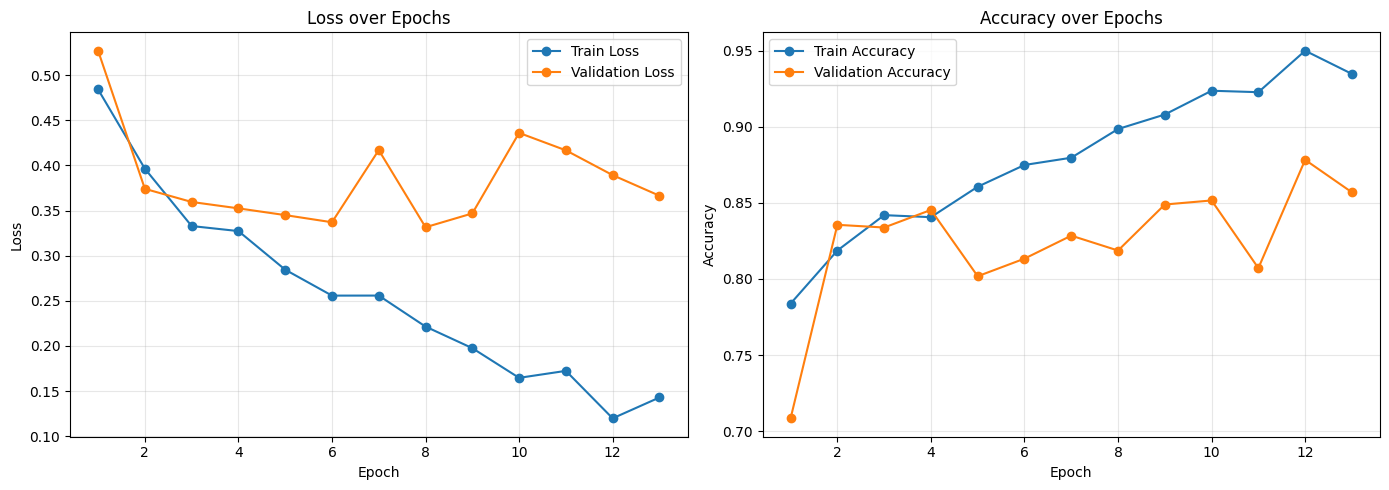

Best epoch (lowest validation loss): Epoch 8


In [ ]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ---- Loss plot ----
axes[0].plot(epochs_range, history["train_loss"], label="Train Loss", marker="o")
axes[0].plot(epochs_range, history["val_loss"], label="Validation Loss", marker="o")
axes[0].set_title("Loss over Epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# ---- Accuracy plot ----
axes[1].plot(epochs_range, history["train_acc"], label="Train Accuracy", marker="o")
axes[1].plot(epochs_range, history["val_acc"], label="Validation Accuracy", marker="o")
axes[1].set_title("Accuracy over Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

best_epoch = history["val_loss"].index(min(history["val_loss"])) + 1
print(f"Best epoch (lowest validation loss): Epoch {best_epoch}")

Load Checkpoint & Run Test Inference

In [ ]:
# ---- Step 1: Load the BEST checkpoint (epoch 6), not the current (possibly overfit) weights ----
checkpoint_path = "/content/drive/MyDrive/XrayDataset_checkpoints/best_model.pth"
model.load_state_dict(torch.load(checkpoint_path, map_location=device))
model.eval()
print(f"✅ Loaded best checkpoint from: {checkpoint_path}")

# ---- Step 2: Run inference on the entire Test set ----
all_predictions = []
all_true_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        predicted_classes = outputs.argmax(dim=1).cpu()

        all_predictions.extend(predicted_classes.tolist())
        all_true_labels.extend(labels.tolist())

print(f"✅ Inference complete on Test set.")
print(f"Total test images evaluated: {len(all_true_labels)}")

✅ Loaded best checkpoint from: /content/drive/MyDrive/XrayDataset_checkpoints/best_model.pth
✅ Inference complete on Test set.
Total test images evaluated: 1126


Accuracy & Per-Class Classification Report

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

overall_accuracy = accuracy_score(all_true_labels, all_predictions)

print(f"--- Overall Test Accuracy: {overall_accuracy:.4f} ({overall_accuracy*100:.2f}%) ---\n")

print("--- Per-Class Report ---")
report = classification_report(
    all_true_labels,
    all_predictions,
    target_names=class_names,
    digits=3
)
print(report)

--- Overall Test Accuracy: 0.8357 (83.57%) ---

--- Per-Class Report ---
                     precision    recall  f1-score   support

             Normal      0.968     0.951     0.960       225
Pneumonia_Bacterial      0.836     0.778     0.806       451
    Pneumonia_Viral      0.586     0.684     0.631       225
       Tuberculosis      1.000     0.987     0.993       225

           accuracy                          0.836      1126
          macro avg      0.847     0.850     0.848      1126
       weighted avg      0.845     0.836     0.839      1126



Confusion Matrix

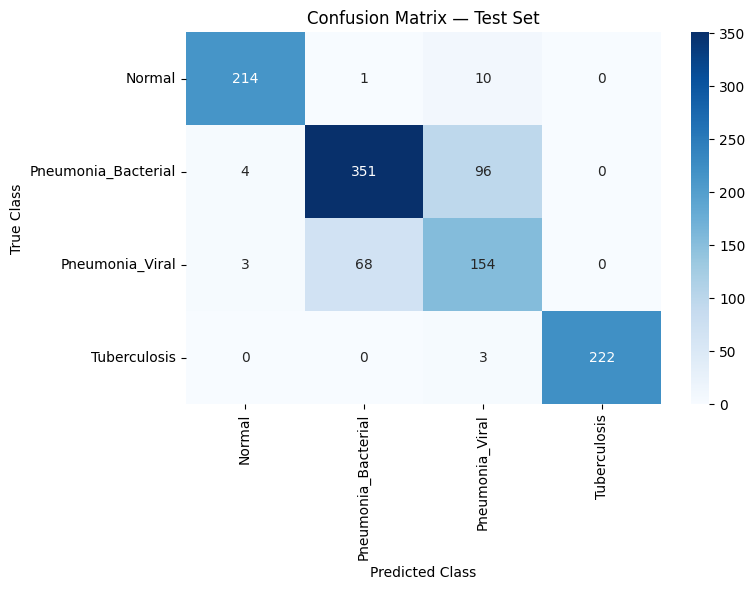

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(all_true_labels, all_predictions)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Confusion Matrix — Test Set")
plt.tight_layout()
plt.show()

Inspect Misclassified Images

Total misclassified images found: 174


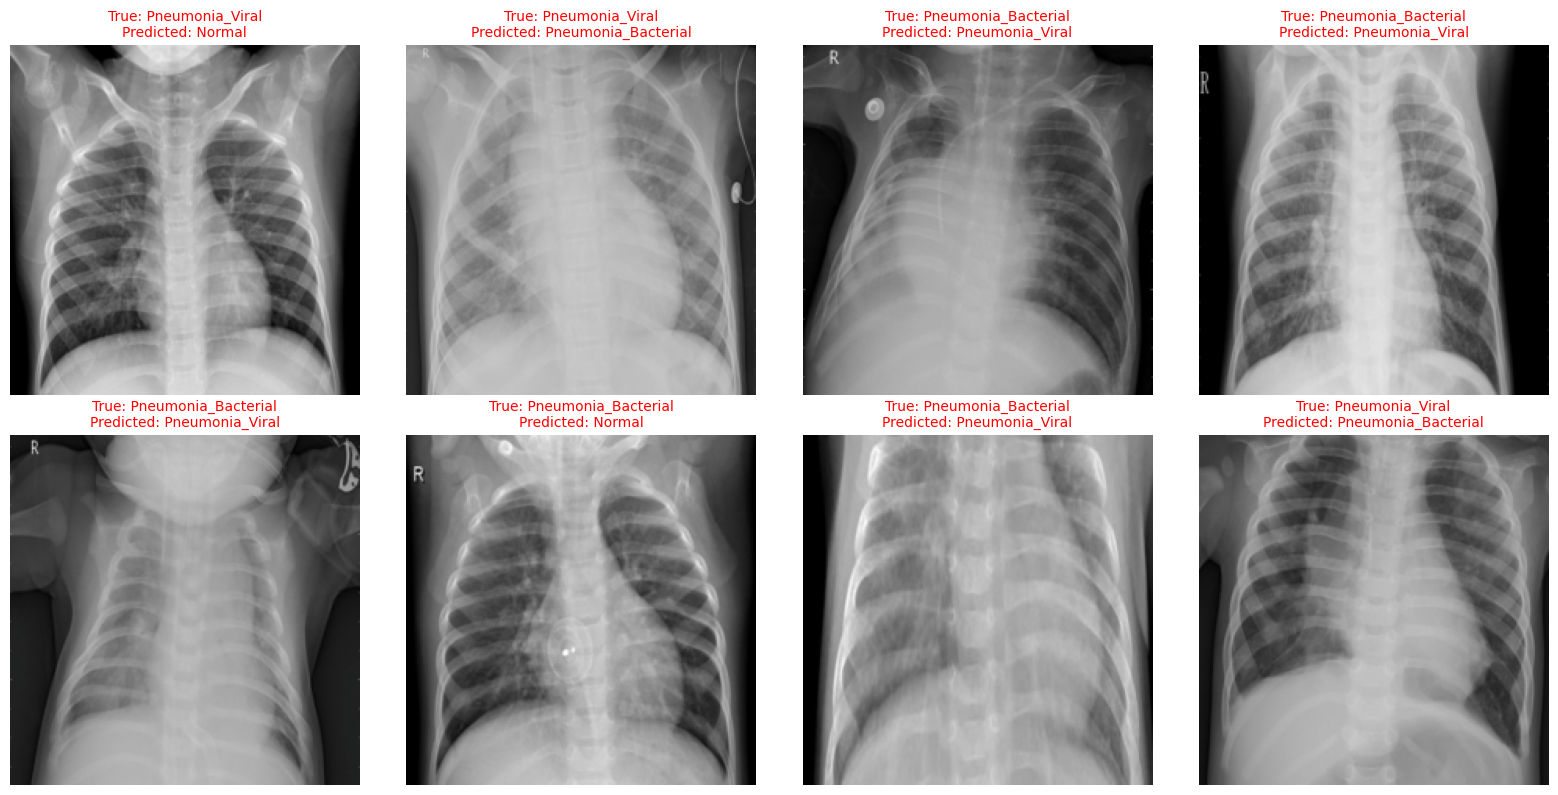

In [ ]:
# Re-run inference, but this time keep track of the actual image tensors too,
# so we can display the specific ones that were misclassified.
misclassified_images = []
misclassified_true = []
misclassified_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images_gpu = images.to(device)
        outputs = model(images_gpu)
        predicted_classes = outputs.argmax(dim=1).cpu()

        for i in range(len(labels)):
            if predicted_classes[i] != labels[i]:
                misclassified_images.append(images[i])
                misclassified_true.append(labels[i].item())
                misclassified_pred.append(predicted_classes[i].item())

print(f"Total misclassified images found: {len(misclassified_images)}")

# ---- Display up to 8 examples ----
num_to_show = min(8, len(misclassified_images))
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for i in range(num_to_show):
    img = unnormalize(misclassified_images[i]).permute(1, 2, 0).numpy()
    img = img.clip(0, 1)

    true_name = class_names[misclassified_true[i]]
    pred_name = class_names[misclassified_pred[i]]

    ax = axes[i // 4, i % 4]
    ax.imshow(img)
    ax.set_title(f"True: {true_name}\nPredicted: {pred_name}", fontsize=10, color="red")
    ax.axis("off")

plt.tight_layout()
plt.show()

Single-Image Prediction Function

In [ ]:
def predict_single_image(image_path, model, transform, class_names, device):
    # Load the image and make sure it's in RGB format (same as training)
    image = Image.open(image_path).convert("RGB")

    # Apply the SAME preprocessing used for validation/test (no augmentation)
    image_tensor = transform(image)

    # Add a "batch dimension" — the model expects [batch_size, 3, 224, 224],
    # but we only have ONE image, so we make it look like a batch of size 1.
    image_tensor = image_tensor.unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        outputs = model(image_tensor)
        probabilities = torch.softmax(outputs, dim=1)[0]  # convert to confidence percentages
        predicted_idx = probabilities.argmax().item()

    predicted_class = class_names[predicted_idx]
    confidence = probabilities[predicted_idx].item()

    # Build a dictionary of ALL class confidences, not just the top prediction
    all_confidences = {
        class_names[i]: probabilities[i].item() for i in range(len(class_names))
    }

    return predicted_class, confidence, all_confidences

print("✅ predict_single_image() function defined and ready to use.")

✅ predict_single_image() function defined and ready to use.


Test Prediction Function on Real Images


Image: Pneumonia-Viral (567).jpg
True label: Pneumonia_Viral
Confidence breakdown:
  Normal: 0.16%
  Pneumonia_Bacterial: 22.57%
  Pneumonia_Viral: 77.18%
  Tuberculosis: 0.10%

Image: Pneumonia-Viral (1547).jpg
True label: Pneumonia_Viral
Confidence breakdown:
  Normal: 0.17%
  Pneumonia_Bacterial: 32.02%
  Pneumonia_Viral: 67.77%
  Tuberculosis: 0.05%

Image: Pneumonia-Bacterial (953).jpg
True label: Pneumonia_Bacterial
Confidence breakdown:
  Normal: 3.56%
  Pneumonia_Bacterial: 74.69%
  Pneumonia_Viral: 21.53%
  Tuberculosis: 0.23%

Image: Normal (2292).jpg
True label: Normal
Confidence breakdown:
  Normal: 61.08%
  Pneumonia_Bacterial: 6.57%
  Pneumonia_Viral: 32.13%
  Tuberculosis: 0.22%


/tmp/ipykernel_2232/1016784138.py:34: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


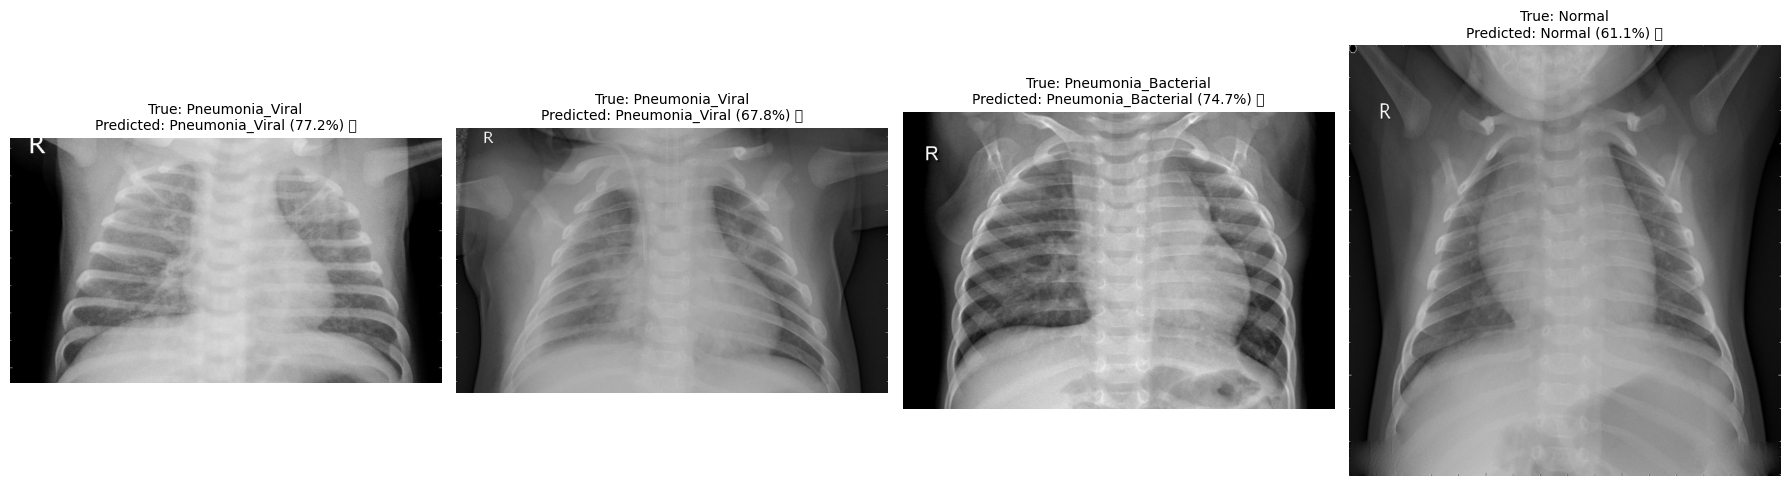

In [ ]:
import random

num_samples = 4
sample_indices = random.sample(range(len(test_paths)), num_samples)

fig, axes = plt.subplots(1, num_samples, figsize=(18, 5))

for i, idx in enumerate(sample_indices):
    image_path = test_paths[idx]
    true_label = test_labels[idx]

    predicted_class, confidence, all_confidences = predict_single_image(
        image_path, model, eval_transform, class_names, device
    )

    # Display the image
    img = Image.open(image_path).convert("RGB")
    axes[i].imshow(img)
    axes[i].axis("off")

    is_correct = "✅" if predicted_class == true_label else "❌"
    axes[i].set_title(
        f"True: {true_label}\nPredicted: {predicted_class} ({confidence*100:.1f}%) {is_correct}",
        fontsize=10
    )

    # Print the full breakdown for this image
    print(f"\nImage: {os.path.basename(image_path)}")
    print(f"True label: {true_label}")
    print("Confidence breakdown:")
    for class_name, conf in all_confidences.items():
        print(f"  {class_name}: {conf*100:.2f}%")

plt.tight_layout()
plt.show()

Convert to TorchScript

In [ ]:
# Load the best checkpoint again, to be 100% sure we're exporting the right weights
model.load_state_dict(torch.load(checkpoint_path, map_location=device))
model.eval()
model_cpu = model.to("cpu")  # mobile devices run on CPU, so we export a CPU version

# Tracing requires one real example input, matching the exact shape the model expects
example_input = torch.randn(1, 3, 224, 224)  # 1 image, 3 channels, 224x224

with torch.no_grad():
    traced_model = torch.jit.trace(model_cpu, example_input)

print("✅ Model successfully converted to TorchScript.")

# Quick sanity check: does the traced version give the same output as the original?
with torch.no_grad():
    original_output = model_cpu(example_input)
    traced_output = traced_model(example_input)

outputs_match = torch.allclose(original_output, traced_output, atol=1e-5)
print(f"Traced model output matches original model output: {outputs_match}")

# Save the TorchScript version to Drive
torchscript_path = "/content/drive/MyDrive/XrayDataset_checkpoints/model_torchscript.pt"
traced_model.save(torchscript_path)
print(f"Saved TorchScript model to: {torchscript_path}")

/tmp/ipykernel_2232/3675183944.py:39: TracerWarning: Converting a tensor to a Python float might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  u = max(1, int(self.sample_factor * math.log(seq_len)))
/tmp/ipykernel_2232/3675183944.py:40: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  u = min(u, seq_len)  # never select more queries than actually exist


✅ Model successfully converted to TorchScript.
Traced model output matches original model output: True
Saved TorchScript model to: /content/drive/MyDrive/XrayDataset_checkpoints/model_torchscript.pt


Mobile Optimization & Export

In [ ]:
from torch.utils.mobile_optimizer import optimize_for_mobile

# Apply mobile-specific optimizations to the traced model
mobile_optimized_model = optimize_for_mobile(traced_model)

print("✅ Mobile optimization applied.")

# Save in the .ptl format — this is the file your Android app will actually load
ptl_path = "/content/drive/MyDrive/XrayDataset_checkpoints/chest_xray_informer_mobile.ptl"
mobile_optimized_model._save_for_lite_interpreter(ptl_path)

print(f"✅ Mobile-ready model saved to: {ptl_path}")

# Check the file size — important for understanding app download/storage size
file_size_mb = os.path.getsize(ptl_path) / (1024 * 1024)
print(f"File size: {file_size_mb:.2f} MB")

✅ Mobile optimization applied.
✅ Mobile-ready model saved to: /content/drive/MyDrive/XrayDataset_checkpoints/chest_xray_informer_mobile.ptl
File size: 65.31 MB


/tmp/ipykernel_2232/692299671.py:10: DeprecationWarning: Lite Interpreter is deprecated. Please consider switching to ExecuTorch.             https://docs.pytorch.org/executorch/stable/getting-started.html
  mobile_optimized_model._save_for_lite_interpreter(ptl_path)


Verify the Exported Model

In [ ]:
# Load the .ptl file back in, using ONLY PyTorch's generic loading function —
# not the ChestXrayInformer class. This proves it's truly self-contained.
loaded_mobile_model = torch.jit.load(ptl_path)
loaded_mobile_model.eval()

print("✅ .ptl file loaded successfully as a standalone model.")

# Test it with a real image, and compare against the original model
test_image_path = test_paths[0]
test_image = Image.open(test_image_path).convert("RGB")
test_tensor = eval_transform(test_image).unsqueeze(0)

with torch.no_grad():
    original_prediction = model_cpu(test_tensor)
    mobile_prediction = loaded_mobile_model(test_tensor)

predictions_match = torch.allclose(original_prediction, mobile_prediction, atol=1e-4)
print(f"Mobile model prediction matches original: {predictions_match}")

predicted_class_name = class_names[mobile_prediction.argmax(dim=1).item()]
print(f"\nSample prediction using .ptl model: {predicted_class_name}")
print(f"True label for this image: {test_labels[0]}")

# ---- Final Phase 7 summary ----
print("\n--- Phase 7 Export Summary ---")
print(f"TorchScript model: {torchscript_path}")
print(f"Mobile (.ptl) model: {ptl_path}")
print(f"Mobile model file size: {file_size_mb:.2f} MB")
print(f"Verification passed: {predictions_match}")

✅ .ptl file loaded successfully as a standalone model.
Mobile model prediction matches original: False

Sample prediction using .ptl model: Tuberculosis
True label for this image: Pneumonia_Viral

--- Phase 7 Export Summary ---
TorchScript model: /content/drive/MyDrive/XrayDataset_checkpoints/model_torchscript.pt
Mobile (.ptl) model: /content/drive/MyDrive/XrayDataset_checkpoints/chest_xray_informer_mobile.ptl
Mobile model file size: 65.31 MB
Verification passed: False


Debug: Test WITHOUT Mobile Optimization

In [ ]:
# Save the traced model DIRECTLY to .ptl, skipping optimize_for_mobile entirely
debug_ptl_path = "/content/drive/MyDrive/XrayDataset_checkpoints/debug_no_optimization.ptl"
traced_model._save_for_lite_interpreter(debug_ptl_path)

# Load it back fresh, exactly like Cell 3 did
debug_loaded_model = torch.jit.load(debug_ptl_path)
debug_loaded_model.eval()

with torch.no_grad():
    original_prediction = model_cpu(test_tensor)
    debug_prediction = debug_loaded_model(test_tensor)

debug_match = torch.allclose(original_prediction, debug_prediction, atol=1e-4)
print(f"Un-optimized .ptl matches original: {debug_match}")

debug_predicted_class = class_names[debug_prediction.argmax(dim=1).item()]
print(f"Prediction from un-optimized .ptl: {debug_predicted_class}")
print(f"True label: {test_labels[0]}")

/tmp/ipykernel_2232/4051096320.py:3: DeprecationWarning: Lite Interpreter is deprecated. Please consider switching to ExecuTorch.             https://docs.pytorch.org/executorch/stable/getting-started.html
  traced_model._save_for_lite_interpreter(debug_ptl_path)


Un-optimized .ptl matches original: True
Prediction from un-optimized .ptl: Normal
True label: Pneumonia_Viral


Final Export

In [ ]:
# NOTE: We deliberately skip optimize_for_mobile() here.
# It was found to corrupt predictions for this model, likely because its
# operator-fusion pass mishandles the topk/gather/scatter operations used
# in our custom ProbSparse attention (Phase 3, Cell 3) — these are unusual
# operations that most mobile-optimized models don't use.

final_ptl_path = "/content/drive/MyDrive/XrayDataset_checkpoints/chest_xray_informer_final.ptl"
traced_model._save_for_lite_interpreter(final_ptl_path)

file_size_mb = os.path.getsize(final_ptl_path) / (1024 * 1024)
print(f"✅ Final mobile-ready model saved to: {final_ptl_path}")
print(f"File size: {file_size_mb:.2f} MB")

/tmp/ipykernel_2232/409844685.py:8: DeprecationWarning: Lite Interpreter is deprecated. Please consider switching to ExecuTorch.             https://docs.pytorch.org/executorch/stable/getting-started.html
  traced_model._save_for_lite_interpreter(final_ptl_path)


✅ Final mobile-ready model saved to: /content/drive/MyDrive/XrayDataset_checkpoints/chest_xray_informer_final.ptl
File size: 65.60 MB


Class-wise Classification Report as a Formatted Table

In [ ]:
# ---- Step 1: Load the BEST checkpoint (epoch 6) ----
checkpoint_path = "/content/drive/MyDrive/XrayDataset_checkpoints/best_model.pth"
model.load_state_dict(torch.load(checkpoint_path, map_location=device))
model = model.to(device)   # <-- NEW: move model back to GPU (it got moved to CPU during Phase 7 export)
model.eval()
print(f"✅ Loaded best checkpoint from: {checkpoint_path}")

# ---- Step 2: Run inference on the entire Test set ----
all_predictions = []
all_true_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        predicted_classes = outputs.argmax(dim=1).cpu()

        all_predictions.extend(predicted_classes.tolist())
        all_true_labels.extend(labels.tolist())

print(f"✅ Inference complete on Test set.")
print(f"Total test images evaluated: {len(all_true_labels)}")

✅ Loaded best checkpoint from: /content/drive/MyDrive/XrayDataset_checkpoints/best_model.pth
✅ Inference complete on Test set.
Total test images evaluated: 1126


In [ ]:
import pandas as pd
from sklearn.metrics import classification_report

report_dict = classification_report(
    all_true_labels,
    all_predictions,
    target_names=class_names,
    output_dict=True,
    digits=3
)

report_df = pd.DataFrame(report_dict).transpose().round(3)

print("=== Classification Report Table ===\n")
print(report_df)

=== Classification Report Table ===

                     precision  recall  f1-score   support
Normal                   0.965   0.973     0.969   225.000
Pneumonia_Bacterial      0.911   0.707     0.797   451.000
Pneumonia_Viral          0.587   0.840     0.691   225.000
Tuberculosis             0.991   1.000     0.996   225.000
accuracy                 0.845   0.845     0.845     0.845
macro avg                0.864   0.880     0.863  1126.000
weighted avg             0.873   0.845     0.850  1126.000


Classification Report — Cleaned for Final Report

In [ ]:
# Fix the "accuracy" row — it should only show the overall accuracy value once,
# with blank cells elsewhere, since precision/recall/f1 don't individually apply to "accuracy" itself.
report_df_clean = report_df.copy()
report_df_clean.loc["accuracy", ["precision", "recall", "support"]] = ""

print("=== Classification Report Table (Cleaned) ===\n")
print(report_df_clean)

=== Classification Report Table (Cleaned) ===

                    precision recall  f1-score support
Normal                  0.965  0.973     0.969   225.0
Pneumonia_Bacterial     0.911  0.707     0.797   451.0
Pneumonia_Viral         0.587   0.84     0.691   225.0
Tuberculosis            0.991    1.0     0.996   225.0
accuracy                                 0.845        
macro avg               0.864   0.88     0.863  1126.0
weighted avg            0.873  0.845     0.850  1126.0


/tmp/ipykernel_2232/691725702.py:4: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  report_df_clean.loc["accuracy", ["precision", "recall", "support"]] = ""
/tmp/ipykernel_2232/691725702.py:4: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  report_df_clean.loc["accuracy", ["precision", "recall", "support"]] = ""
/tmp/ipykernel_2232/691725702.py:4: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  report_df_clean.loc["accuracy", ["precision", "recall", "support"]] = ""


Export Classification Report as CSV and Excel

In [ ]:
# Save both as CSV (universal, opens in Excel/Sheets) and Excel (.xlsx) formats
csv_path = "/content/drive/MyDrive/XrayDataset_checkpoints/classification_report.csv"
xlsx_path = "/content/drive/MyDrive/XrayDataset_checkpoints/classification_report.xlsx"

report_df_clean.to_csv(csv_path)
report_df_clean.to_excel(xlsx_path)

print(f"✅ Saved CSV to: {csv_path}")
print(f"✅ Saved Excel file to: {xlsx_path}")

✅ Saved CSV to: /content/drive/MyDrive/XrayDataset_checkpoints/classification_report.csv
✅ Saved Excel file to: /content/drive/MyDrive/XrayDataset_checkpoints/classification_report.xlsx


Confusion Matrix — Labeled Table for Report

In [ ]:
from sklearn.metrics import confusion_matrix

# Reuses the same all_true_labels / all_predictions from earlier — no new inference needed
cm = confusion_matrix(all_true_labels, all_predictions)

# Turn it into a labeled table: rows = actual class, columns = predicted class
cm_df = pd.DataFrame(cm, index=class_names, columns=class_names)
cm_df.index.name = "True \\ Predicted"

print("=== Confusion Matrix Table ===\n")
print(cm_df)

# Save as CSV and Excel too
cm_csv_path = "/content/drive/MyDrive/XrayDataset_checkpoints/confusion_matrix.csv"
cm_xlsx_path = "/content/drive/MyDrive/XrayDataset_checkpoints/confusion_matrix.xlsx"

cm_df.to_csv(cm_csv_path)
cm_df.to_excel(cm_xlsx_path)

print(f"\n✅ Saved CSV to: {cm_csv_path}")
print(f"✅ Saved Excel file to: {cm_xlsx_path}")

=== Confusion Matrix Table ===

                     Normal  Pneumonia_Bacterial  Pneumonia_Viral  \
True \ Predicted                                                    
Normal                  219                    0                4   
Pneumonia_Bacterial       3                  319              129   
Pneumonia_Viral           5                   31              189   
Tuberculosis              0                    0                0   

                     Tuberculosis  
True \ Predicted                   
Normal                          2  
Pneumonia_Bacterial             0  
Pneumonia_Viral                 0  
Tuberculosis                  225  

✅ Saved CSV to: /content/drive/MyDrive/XrayDataset_checkpoints/confusion_matrix.csv
✅ Saved Excel file to: /content/drive/MyDrive/XrayDataset_checkpoints/confusion_matrix.xlsx


Class Distribution Table (Train/Val/Test/Overall)

In [ ]:
from collections import Counter

train_counts = Counter(train_labels)
val_counts = Counter(val_labels)
test_counts = Counter(test_labels)

distribution_data = {
    "Train": [train_counts[c] for c in class_names],
    "Validation": [val_counts[c] for c in class_names],
    "Test": [test_counts[c] for c in class_names],
}

distribution_df = pd.DataFrame(distribution_data, index=class_names)
distribution_df["Total"] = distribution_df.sum(axis=1)

# Add an "Overall Total" row at the bottom
distribution_df.loc["Overall Total"] = distribution_df.sum()

print("=== Class Distribution Table ===\n")
print(distribution_df)

# Save as CSV and Excel
dist_csv_path = "/content/drive/MyDrive/XrayDataset_checkpoints/class_distribution.csv"
dist_xlsx_path = "/content/drive/MyDrive/XrayDataset_checkpoints/class_distribution.xlsx"

distribution_df.to_csv(dist_csv_path)
distribution_df.to_excel(dist_xlsx_path)

print(f"\n✅ Saved CSV to: {dist_csv_path}")
print(f"✅ Saved Excel file to: {dist_xlsx_path}")

=== Class Distribution Table ===

                     Train  Validation  Test  Total
Normal                1050         225   225   1500
Pneumonia_Bacterial   2100         450   451   3001
Pneumonia_Viral       1050         225   225   1500
Tuberculosis          1050         225   225   1500
Overall Total         5250        1125  1126   7501

✅ Saved CSV to: /content/drive/MyDrive/XrayDataset_checkpoints/class_distribution.csv
✅ Saved Excel file to: /content/drive/MyDrive/XrayDataset_checkpoints/class_distribution.xlsx


Final Model-Performance Summary Table

In [ ]:
summary_data = {
    "Metric": [
        "Model Architecture",
        "CNN Backbone",
        "Total Parameters",
        "Total Dataset Size",
        "Train / Val / Test Split",
        "Best Checkpoint Epoch",
        "Best Validation Loss",
        "Overall Test Accuracy",
        "Macro Avg F1-score",
        "Weighted Avg F1-score",
        "Best Performing Class",
        "Weakest Performing Class",
        "Exported Model Format",
        "Exported Model Size"
    ],
    "Value": [
        "CNN + Informer-style Transformer (ProbSparse Attention)",
        "ResNet-18 (Pretrained, ImageNet)",
        "17,116,484",
        "7501 images (4 classes)",
        "5250 / 1125 / 1126",
        "Epoch 6",
        "0.3233",
        f"{report_dict['accuracy']*100:.2f}%",
        f"{report_dict['macro avg']['f1-score']:.3f}",
        f"{report_dict['weighted avg']['f1-score']:.3f}",
        "Tuberculosis (F1: 0.996)",
        "Pneumonia_Viral (F1: 0.691)",
        "TorchScript (.ptl, Lite Interpreter)",
        "65.59 MB"
    ]
}

summary_df = pd.DataFrame(summary_data)

print("=== Final Model-Performance Summary Table ===\n")
print(summary_df.to_string(index=False))

# Save as CSV and Excel
summary_csv_path = "/content/drive/MyDrive/XrayDataset_checkpoints/final_summary_table.csv"
summary_xlsx_path = "/content/drive/MyDrive/XrayDataset_checkpoints/final_summary_table.xlsx"

summary_df.to_csv(summary_csv_path, index=False)
summary_df.to_excel(summary_xlsx_path, index=False)

print(f"\n✅ Saved CSV to: {summary_csv_path}")
print(f"✅ Saved Excel file to: {summary_xlsx_path}")

=== Final Model-Performance Summary Table ===

                  Metric                                                   Value
      Model Architecture CNN + Informer-style Transformer (ProbSparse Attention)
            CNN Backbone                        ResNet-18 (Pretrained, ImageNet)
        Total Parameters                                              17,116,484
      Total Dataset Size                                 7501 images (4 classes)
Train / Val / Test Split                                      5250 / 1125 / 1126
   Best Checkpoint Epoch                                                 Epoch 6
    Best Validation Loss                                                  0.3233
   Overall Test Accuracy                                                  84.55%
      Macro Avg F1-score                                                   0.863
   Weighted Avg F1-score                                                   0.850
   Best Performing Class                                Tuberc

Verify All Exported Files Exist

In [ ]:
checkpoint_folder = "/content/drive/MyDrive/XrayDataset_checkpoints"

expected_files = [
    "classification_report.csv",
    "classification_report.xlsx",
    "confusion_matrix.csv",
    "confusion_matrix.xlsx",
    "class_distribution.csv",
    "class_distribution.xlsx",
    "final_summary_table.csv",
    "final_summary_table.xlsx",
]

print("=== Documentation Files Check ===\n")
all_present = True
for filename in expected_files:
    filepath = os.path.join(checkpoint_folder, filename)
    if os.path.exists(filepath):
        size_kb = os.path.getsize(filepath) / 1024
        print(f"  ✅ {filename} ({size_kb:.1f} KB)")
    else:
        print(f"  ❌ MISSING: {filename}")
        all_present = False

print()
if all_present:
    print("✅ All documentation files are present in your Drive checkpoints folder.")
else:
    print("⚠️ Some files are missing — re-run the corresponding earlier step.")

=== Documentation Files Check ===

  ✅ classification_report.csv (0.3 KB)
  ✅ classification_report.xlsx (5.1 KB)
  ✅ confusion_matrix.csv (0.2 KB)
  ✅ confusion_matrix.xlsx (5.0 KB)
  ✅ class_distribution.csv (0.2 KB)
  ✅ class_distribution.xlsx (5.0 KB)
  ✅ final_summary_table.csv (0.6 KB)
  ✅ final_summary_table.xlsx (5.3 KB)

✅ All documentation files are present in your Drive checkpoints folder.


In [ ]:
!find /content/drive/MyDrive -type f \( -name "*.pt" -o -name "*.ptl" -o -name "*.pth" -o -name "*.onnx" \)

/content/drive/MyDrive/XrayDataset_checkpoints/best_model.pth
/content/drive/MyDrive/XrayDataset_checkpoints/model_torchscript.pt
/content/drive/MyDrive/XrayDataset_checkpoints/debug_no_optimization.ptl
/content/drive/MyDrive/XrayDataset_checkpoints/chest_xray_informer_final.ptl
/content/drive/MyDrive/XrayDataset_checkpoints/chest_xray_informer_mobile.ptl


In [ ]:
import torch

model_path = "/content/drive/MyDrive/XrayDataset_checkpoints/chest_xray_informer_mobile.ptl"

print("File exists:", os.path.exists(model_path))
print("File size:", os.path.getsize(model_path) / (1024 * 1024), "MB")

File exists: True
File size: 65.30543231964111 MB


In [ ]:
import torch

model_path = "/content/drive/MyDrive/XrayDataset_checkpoints/chest_xray_informer_mobile.ptl"

try:
    model = torch.jit.load(model_path, map_location="cpu")
    model.eval()
    print("✅ TorchScript model loaded successfully!")
    print(model)
except Exception as e:
    print("❌ Model loading error:")
    print(e)

✅ TorchScript model loaded successfully!
RecursiveScriptModule(original_name=ChestXrayInformer)


In [ ]:
import torch

model_path = "/content/drive/MyDrive/XrayDataset_checkpoints/chest_xray_informer_mobile.ptl"

model = torch.jit.load(model_path, map_location="cpu")
model.eval()

print("MODEL:")
print(model)

print("\nMETHODS:")
print(model._c._method_names())

MODEL:
RecursiveScriptModule(original_name=ChestXrayInformer)

METHODS:
['forward']


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

model_path = "/content/drive/MyDrive/XrayDataset_checkpoints/chest_xray_informer_mobile.ptl"

print("File exists:", os.path.exists(model_path))

File exists: True


In [ ]:
import torch

model = torch.jit.load(model_path, map_location="cpu")
model.eval()

print("✅ Model loaded successfully")
print("Methods:", model._c._method_names())
print("Forward schema:", model.forward.schema)

✅ Model loaded successfully
Methods: ['forward']
Forward schema: forward(__torch__.___torch_mangle_1075.ChestXrayInformer self, Tensor x) -> Tensor


In [ ]:
import torch
from torchvision import transforms

IMAGE_SIZE = (224, 224)

eval_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("✅ eval_transform recreated successfully!")

✅ eval_transform recreated successfully!


In [ ]:

from torchvision import transforms

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Transform ready!")


Transform ready!


In [ ]:

import torch
import time
from PIL import Image

# ==========================================
# 1. MODEL PATH
# ==========================================

final_ptl_path = "/content/drive/MyDrive/XrayDataset_checkpoints/chest_xray_informer_final.ptl"

# ==========================================
# 2. LOAD MODEL
# ==========================================

final_mobile_model = torch.jit.load(
    final_ptl_path,
    map_location="cpu"
)

final_mobile_model.eval()

print("Final PTL loaded successfully!")

# ==========================================
# 3. TEST IMAGE
# ==========================================

test_image_path = "/content/drive/MyDrive/XrayDataset/Normal/Normal (2057).jpg"
true_class = "Normal"

test_image = Image.open(test_image_path).convert("RGB")

# eval_transform must already be defined in Colab
test_tensor = eval_transform(test_image).unsqueeze(0)

print("Input tensor shape:", test_tensor.shape)

# ==========================================
# 4. CLASS NAMES
# ==========================================

class_names = [
    "Normal",
    "Pneumonia_Bacterial",
    "Pneumonia_Viral",
    "Tuberculosis"
]

# ==========================================
# 5. WARM-UP
# ==========================================

print("\nRunning 3 warm-up inferences...")

with torch.inference_mode():
    for _ in range(3):
        _ = final_mobile_model(test_tensor)

print("Warm-up completed!")

# ==========================================
# 6. MEASURE INFERENCE LATENCY
# ==========================================

latencies_ms = []

print("Measuring 20 inference runs...")

with torch.inference_mode():
    for _ in range(20):

        start_ns = time.perf_counter_ns()

        final_output = final_mobile_model(test_tensor)

        end_ns = time.perf_counter_ns()

        latency_ms = (end_ns - start_ns) / 1_000_000
        latencies_ms.append(latency_ms)

# ==========================================
# 7. PREDICTION AND PROBABILITIES
# ==========================================

probabilities = torch.softmax(final_output, dim=1)[0]

predicted_index = probabilities.argmax().item()
predicted_class = class_names[predicted_index]
confidence = probabilities[predicted_index].item()

# ==========================================
# 8. LATENCY STATISTICS
# ==========================================

avg_latency = sum(latencies_ms) / len(latencies_ms)

sorted_latencies = sorted(latencies_ms)
median_latency = (
    sorted_latencies[len(sorted_latencies) // 2]
    if len(sorted_latencies) % 2 == 1
    else (
        sorted_latencies[len(sorted_latencies) // 2 - 1]
        + sorted_latencies[len(sorted_latencies) // 2]
    ) / 2
)

# ==========================================
# 9. DISPLAY RESULTS
# ==========================================

print("\n========== FINAL PTL RESULT ==========")

print("True class       :", true_class)
print("Predicted class  :", predicted_class)
print(f"Confidence       : {confidence * 100:.2f}%")

print("\nClass probabilities:")

for i, class_name in enumerate(class_names):
    print(
        f"{class_name}: "
        f"{probabilities[i].item() * 100:.2f}%"
    )

print("\n========== LATENCY RESULTS ==========")

print("Measured runs:", len(latencies_ms))
print(f"Average latency: {avg_latency:.3f} ms")
print(f"Median latency : {median_latency:.3f} ms")
print(f"Minimum latency: {min(latencies_ms):.3f} ms")
print(f"Maximum latency: {max(latencies_ms):.3f} ms")

print("\nPreprocessing time: Not included")
print("Image selection time: Not included")
print("Device: Google Colab CPU")

print("\nTest completed successfully!")


Final PTL loaded successfully!
Input tensor shape: torch.Size([1, 3, 224, 224])

Running 3 warm-up inferences...
Warm-up completed!
Measuring 20 inference runs...

========== FINAL PTL RESULT ==========
True class       : Normal
Predicted class  : Normal
Confidence       : 99.15%

Class probabilities:
Normal: 99.15%
Pneumonia_Bacterial: 0.20%
Pneumonia_Viral: 0.63%
Tuberculosis: 0.01%

========== LATENCY RESULTS ==========
Measured runs: 20
Average latency: 93.356 ms
Median latency : 96.904 ms
Minimum latency: 61.257 ms
Maximum latency: 119.640 ms

Preprocessing time: Not included
Image selection time: Not included
Device: Google Colab CPU

Test completed successfully!
